# 05 · Selección del modelo ganador y registro

Se comparan los dos mejores modelos del tuning, **hist gradient boosting** (mejor PR-AUC en CV) y **random forest** (segundo mejor), con toda la evidencia que pide la decisión:
1. ¿La diferencia en CV supera la variación entre pliegues? Se compara además con un esquema de CV al azar.
2. Evaluación **una sola vez** en el conjunto de prueba (cortes del 21 al 24 de octubre).
3. **Métrica de negocio:** cuánto recaudo y capital captura cada modelo con la capacidad real del call center, y cuánto cuesta el error más caro.
4. **Efecto incremental** (S-learner), como pidió la retroalimentación del PSet 1.
5. Costo y explicabilidad.
6. Registro en el Model Registry (`champion` y `challenger`), recuperación del modelo y exportación de las corridas.

## 1. Datos y modelos del registro

In [1]:
import sys
sys.path.append("..")

import logging
import subprocess
import time
import warnings

import matplotlib.pyplot as plt
import mlflow
import mlflow.sklearn
import numpy as np
import pandas as pd
from mlflow import MlflowClient
from mlflow.models import infer_signature
from sklearn.base import clone
from sklearn.inspection import permutation_importance
from sklearn.metrics import average_precision_score
from sklearn.model_selection import KFold, cross_val_score
from src.datos import TABLA, huella
from src.pipeline import FIN_ENTRENAMIENTO, INICIO_PRUEBA, cargar_base, cargar_y_dividir

logging.getLogger("mlflow").setLevel(logging.ERROR)
warnings.filterwarnings("ignore", module="mlflow")

X_ent, X_prueba, y_ent, y_prueba, grupos_ent = cargar_y_dividir()
base = cargar_base()
prueba = base[base["fecha_corte"] >= INICIO_PRUEBA].reset_index(drop=True)
huella_datos = huella(pd.concat([X_ent, y_ent], axis=1))
commit = subprocess.check_output(["git", "rev-parse", "--short", "HEAD"]).decode().strip()
mlflow.set_experiment("priorizacion-cartera")
cliente = MlflowClient()

# Corridas padre del tuning (notebook 04)
corridas = mlflow.search_runs(experiment_names=["priorizacion-cartera"], filter_string="tags.fase = 'tuning'")
padres = corridas[corridas["tags.mlflow.runName"].str.startswith("tuning ")].set_index("tags.mlflow.runName")

GANADOR, SEGUNDO = "tuning hist gradient boosting", "tuning random forest"
run_ganador, run_segundo = padres.loc[GANADOR, "run_id"], padres.loc[SEGUNDO, "run_id"]
ganador = mlflow.sklearn.load_model(f"runs:/{run_ganador}/modelo")
segundo = mlflow.sklearn.load_model(f"runs:/{run_segundo}/modelo")

print("¿Mismas filas de prueba?:", len(prueba) == len(X_prueba))
padres[["run_id", "metrics.pr_auc_cv_promedio", "metrics.pr_auc_cv_desviacion", "metrics.brecha"]].round(4)

¿Mismas filas de prueba?: True


,run_id,metrics.pr_auc_cv_promedio,metrics.pr_auc_cv_desviacion,metrics.brecha
tags.mlflow.runName,,,,
tuning random forest,3423c896f33e4256a49a069a6b92ffc9,0.4491,0.0223,0.2053
tuning hist gradient boosting,b74e7c145aea4401ac59945aba0c3501,0.4589,0.0215,0.0807
tuning regresion logistica,f7a43c510afe4fcf86e1c377a3d4f732,0.4453,0.0256,0.0080


## 2. ¿La diferencia entre el ganador y el segundo es real?

Se muestra la PR-AUC de cada pliegue de la validación por crédito (leída del registro de MLflow) y, para comparar, la de una validación **al azar** (`KFold` con mezcla), que el diagnóstico del notebook 03 mostró que es optimista.

In [2]:
pliegues = [f"metrics.pr_auc_pliegue_{i}" for i in range(1, 6)]
tabla_cv = padres.loc[[GANADOR, SEGUNDO], pliegues].T
tabla_cv.index = [f"pliegue {i}" for i in range(1, 6)]
tabla_cv.loc["promedio"] = tabla_cv.mean()
tabla_cv.loc["desviacion"] = tabla_cv.iloc[:5].std(ddof=0)

al_azar = KFold(n_splits=5, shuffle=True, random_state=42)
for nombre, modelo in [(GANADOR, ganador), (SEGUNDO, segundo)]:
    notas = cross_val_score(clone(modelo), X_ent, y_ent, cv=al_azar, scoring="average_precision")
    tabla_cv.loc["al azar: promedio", nombre] = notas.mean()
    tabla_cv.loc["al azar: desviacion", nombre] = notas.std()

diferencia = tabla_cv.loc["promedio", GANADOR] - tabla_cv.loc["promedio", SEGUNDO]
print(f"Diferencia en CV por crédito: {diferencia:.4f} | desviación entre pliegues: "
      f"{tabla_cv.loc['desviacion', GANADOR]:.4f} y {tabla_cv.loc['desviacion', SEGUNDO]:.4f}")
print("Pliegues en que gana el ganador:", (tabla_cv.iloc[:5][GANADOR] > tabla_cv.iloc[:5][SEGUNDO]).sum(), "de 5")
tabla_cv.round(4)

Diferencia en CV por crédito: 0.0098 | desviación entre pliegues: 0.0215 y 0.0223
Pliegues en que gana el ganador: 5 de 5


tags.mlflow.runName,tuning hist gradient boosting,tuning random forest
pliegue 1,0.4504,0.4287
pliegue 2,0.4548,0.4411
pliegue 3,0.4997,0.4910
pliegue 4,0.4359,0.4336
pliegue 5,0.4535,0.4511
promedio,0.4589,0.4491
desviacion,0.0215,0.0223
al azar: promedio,0.5067,0.5785
al azar: desviacion,0.0099,0.0066


**Hallazgo: la diferencia promedio es chica, pero el boosting gana en los 5 pliegues.**
- **Evidencia:** en CV por crédito, el hist gradient boosting obtiene 0.459 ± 0.022 y el random forest 0.449 ± 0.022. La diferencia (0.010) es menor que la desviación entre pliegues, así que por sí sola no demuestra que uno sea mejor. Pero, comparando pliegue por pliegue (los mismos créditos), el boosting gana en los 5: la ventaja es pequeña, pero consistente.
- **Comparación con CV al azar:** con pliegues aleatorios, las métricas suben a 0.507 (boosting) y 0.579 (random forest), y el orden se invierte. Es el mismo efecto del diagnóstico del notebook 03: el random forest reconoce mejor a los créditos repetidos, así que la CV al azar lo favorece de forma engañosa.

## 3. Evaluación en el conjunto de prueba (una sola vez)

Los dos modelos y las dos líneas base se evalúan sobre los cortes del 21 al 24 de octubre, que ningún modelo vio. Hay una brecha de 7 días con el entrenamiento, para que ningún target del entrenamiento use días de la prueba.

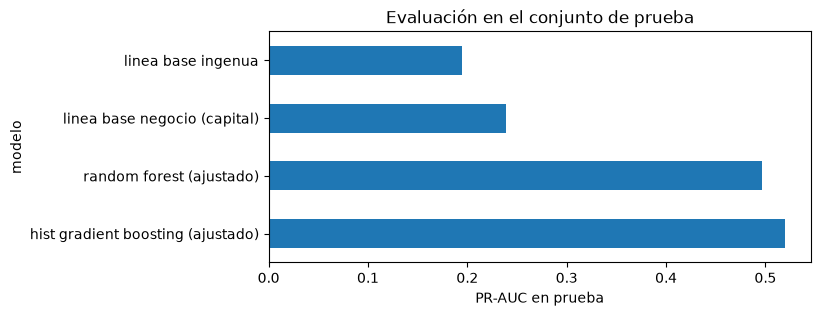

,modelo,pr_auc_prueba
0,hist gradient boosting (ajustado),0.5200
1,random forest (ajustado),0.4968
2,linea base negocio (capital),0.2387
3,linea base ingenua,0.1945


In [3]:
prob_ganador = ganador.predict_proba(X_prueba)[:, 1]
prob_segundo = segundo.predict_proba(X_prueba)[:, 1]

resultados_prueba = pd.DataFrame({
    "modelo": ["hist gradient boosting (ajustado)", "random forest (ajustado)",
               "linea base negocio (capital)", "linea base ingenua"],
    "pr_auc_prueba": [average_precision_score(y_prueba, prob_ganador),
                      average_precision_score(y_prueba, prob_segundo),
                      average_precision_score(y_prueba, X_prueba["capital_insoluto"]),
                      y_prueba.mean()],
}).round(4)

resultados_prueba.plot(x="modelo", y="pr_auc_prueba", kind="barh", legend=False, figsize=(7, 3))
plt.xlabel("PR-AUC en prueba")
plt.title("Evaluación en el conjunto de prueba")
plt.savefig("../docs/figuras/seleccion_prueba.png", bbox_inches="tight")
plt.show()
resultados_prueba

**Hallazgo: en el conjunto de prueba se confirma el orden de la CV.**
- **Evidencia:** PR-AUC en prueba: hist gradient boosting 0.520, random forest 0.497, regla de negocio 0.239 y línea base ingenua 0.195 (la proporción de pago en la prueba es 19.45%). El modelo ganador ordena a los que pagan más del doble de bien que la regla actual.
- La PR-AUC en prueba es mayor que en CV (0.520 frente a 0.459), en parte porque en la prueba la proporción de pago es más alta (19.45% frente a 15.65% en el entrenamiento): los días de prueba están cerca de fin de mes, cuando muchos clientes se comprometen a pagar.

## 4. Métrica de negocio y umbral de decisión

**Capacidad real:** 10 cobradores × 60 gestiones = **600 llamadas al día**, para unos 3,000 créditos en mora.

**Costo de cada error:**
- **Falso positivo** (llamar a quien no paga): el costo de una gestión, **≈ US$0.60**. Un cobrador le cuesta a la empresa ≈ US$806 al mes (SBU 2026 de US$482 con décimos, IESS y fondo de reserva ≈ US$656, más hasta US$150 de comisión) y hace ≈ 1,440 gestiones al mes (60 diarias de lunes a viernes y unas 30 los sábados, en horas extra).
- **Falso negativo** (no priorizar a quien sí paga): se deja sin gestionar su **cuota más vencida**, de varios cientos de dólares. Es el **error más caro**: cientos de veces el costo de una llamada.

**Umbral de decisión:** por costo, convendría llamar a todo crédito con probabilidad de pago mayor que costo de la gestión / cuota (≈ 0.60 / 400 ≈ 0.2%), es decir, a casi todos. Como la capacidad no lo permite, el umbral práctico es **el puntaje del crédito número 600 de cada día**.

**Cómo se ordena la lista** (regla del PSet 1): **probabilidad de pago × capital insoluto**. La probabilidad se calcula suponiendo que el crédito **será gestionado** (`gestionado_7d = 1`), porque al armar la lista todavía no se sabe a quién se llamará.

**Métricas por modelo, sumando los 4 días de prueba:**
- **Capital normalizado capturado:** capital insoluto de los créditos que pagaron y estaban en la lista (lo que mueve los indicadores PAR).
- **Recaudo no priorizado (costo del error más caro):** cuota más vencida de los créditos que pagaron pero quedaron fuera de la lista.
- **Costo de llamadas sin pago:** llamadas a créditos que no pagaron × US$0.60.

In [4]:
CAPACIDAD = 600
COSTO_GESTION = 0.60


def como_gestionados(X):
    X = X.copy()
    X["gestionado_7d"] = 1
    return X


def metrica_negocio(puntaje):
    tabla = prueba[["fecha_corte", "capital_insoluto", "saldo_cuota_mas_vencida"]].copy()
    tabla["paga"] = y_prueba.to_numpy()
    tabla["puntaje"] = np.asarray(puntaje)
    tabla["posicion"] = tabla.groupby("fecha_corte")["puntaje"].rank(ascending=False, method="first")
    tabla["en_lista"] = tabla["posicion"] <= CAPACIDAD
    pagan_en_lista = tabla["en_lista"] & (tabla["paga"] == 1)
    pagan_fuera = ~tabla["en_lista"] & (tabla["paga"] == 1)
    return {"pagos_en_lista": int(pagan_en_lista.sum()),
            "% pagos capturados": pagan_en_lista.sum() / tabla["paga"].sum() * 100,
            "capital_normalizado_capturado": tabla.loc[pagan_en_lista, "capital_insoluto"].sum(),
            "recaudo_no_priorizado": tabla.loc[pagan_fuera, "saldo_cuota_mas_vencida"].sum(),
            "costo_llamadas_sin_pago": (tabla["en_lista"] & (tabla["paga"] == 0)).sum() * COSTO_GESTION}


capital = X_prueba["capital_insoluto"].to_numpy()
p_ganador = ganador.predict_proba(como_gestionados(X_prueba))[:, 1]
p_segundo = segundo.predict_proba(como_gestionados(X_prueba))[:, 1]

negocio = pd.DataFrame({
    "hist gradient boosting (ajustado)": metrica_negocio(p_ganador * capital),
    "random forest (ajustado)": metrica_negocio(p_segundo * capital),
    "linea base negocio (capital)": metrica_negocio(capital),
}).T.round(1)
negocio

,pagos_en_lista,% pagos capturados,capital_normalizado_capturado,recaudo_no_priorizado,costo_llamadas_sin_pago
hist gradient boosting (ajustado),1008.0,41.3,21438547.9,608066.6,835.2
random forest (ajustado),988.0,40.5,21204249.0,609140.6,847.2
linea base negocio (capital),603.0,24.7,15022457.8,715364.1,1078.2


**Hallazgo: con las mismas 600 llamadas diarias, el modelo captura un 67% más de pagos que la regla actual.**
- **Evidencia (4 días de prueba):**
  - **Pagos en la lista:** 1,008 con el modelo frente a 603 con la regla "mayor capital primero" (41.3% frente a 24.7% de todos los pagos).
  - **Capital normalizado capturado:** US$21.4 millones frente a US$15.0 millones (+US$6.4 millones): el capital que mejora de tramo y mueve los indicadores PAR.
  - **Error más caro (recaudo no priorizado):** US$608 mil frente a US$715 mil: el modelo deja fuera de la lista US$107 mil menos de cuotas de clientes que sí pagaron.
  - **Llamadas sin pago:** US$835 frente a US$1,078. Es un costo mucho menor, que confirma que el error más caro es no priorizar a quien paga.
- El random forest queda muy cerca del boosting (988 pagos), y los dos superan ampliamente a la regla actual.
- **Umbral de decisión:** como no priorizar a quien paga cuesta cientos de veces más que una llamada, el umbral lo define la capacidad: el puntaje del crédito número 600 de cada día.
- **Precaución:** un mismo crédito puede aparecer en la lista varios días seguidos y contar como pago capturado más de una vez, así que los montos sobrestiman el efecto en dinero. La comparación entre modelos sí es justa, porque todos se miden igual.

## 5. Efecto incremental (S-learner)

Retroalimentación del PSet 1: no priorizar a quien pagaría igual sin ser llamado. Con el modelo ganador, cada crédito se predice dos veces:
- **P(paga | gestionado):** con `gestionado_7d = 1`.
- **P(paga | no gestionado):** con `gestionado_7d = 0`.

La diferencia es el **efecto incremental** (uplift) estimado de la gestión. La lista alternativa se ordena por **uplift × capital insoluto**.

**Verificación con los datos de prueba:** se agrupan los créditos en 5 grupos según su uplift estimado y, en cada grupo, se compara la tasa de pago de los que sí fueron gestionados con la de los que no. Si el modelo identifica bien el efecto, la diferencia observada debe crecer con el uplift estimado.

**Limitación:** los cobradores no eligen al azar a quién llamar (sesgo de selección), así que la diferencia observada mezcla el efecto de la llamada con el tipo de cliente. La validación definitiva sería un piloto con grupo de control aleatorio.

Pagos capturados — prob × capital: 1008 | uplift × capital: 470


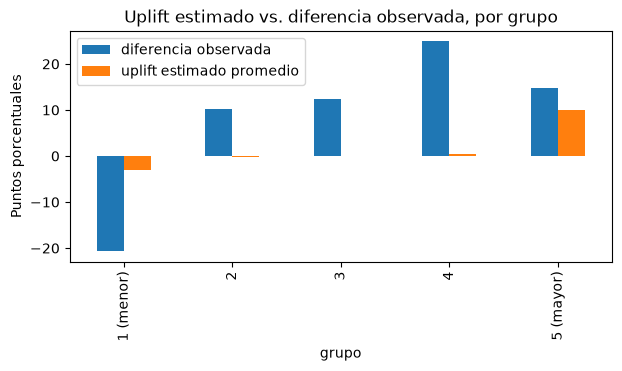

,% paga sin gestión,% paga con gestión,diferencia observada,uplift estimado promedio
grupo,,,,
1 (menor),56.5,35.7,-20.7,-3.1
2,12.2,22.4,10.2,-0.2
3,3.0,15.5,12.4,0.0
4,5.2,30.1,24.9,0.4
5 (mayor),9.6,24.4,14.8,9.9


In [5]:
sin_gestion = X_prueba.copy()
sin_gestion["gestionado_7d"] = 0
p_sin_gestion = ganador.predict_proba(sin_gestion)[:, 1]
uplift = p_ganador - p_sin_gestion

verificacion = pd.DataFrame({"uplift_estimado": uplift, "gestionado": X_prueba["gestionado_7d"].to_numpy(),
                             "paga": y_prueba.to_numpy()})
verificacion["grupo"] = pd.qcut(verificacion["uplift_estimado"].rank(method="first"), 5,
                                labels=["1 (menor)", "2", "3", "4", "5 (mayor)"])
tasas = verificacion.pivot_table(index="grupo", columns="gestionado", values="paga", aggfunc="mean", observed=False) * 100
tasas.columns = ["% paga sin gestión", "% paga con gestión"]
tasas["diferencia observada"] = tasas["% paga con gestión"] - tasas["% paga sin gestión"]
tasas["uplift estimado promedio"] = verificacion.groupby("grupo", observed=False)["uplift_estimado"].mean() * 100

lista_prob = metrica_negocio(p_ganador * capital)
lista_uplift = metrica_negocio(uplift * capital)
print("Pagos capturados — prob × capital:", lista_prob["pagos_en_lista"],
      "| uplift × capital:", lista_uplift["pagos_en_lista"])

tasas.round(1).plot(y=["diferencia observada", "uplift estimado promedio"], kind="bar", figsize=(7, 3))
plt.ylabel("Puntos porcentuales")
plt.title("Uplift estimado vs. diferencia observada, por grupo")
plt.savefig("../docs/figuras/seleccion_uplift.png", bbox_inches="tight")
plt.show()
tasas.round(1)

**Hallazgo: el S-learner capta la dirección del efecto en los extremos, pero subestima su tamaño.**
- **Evidencia:** en los grupos 2 a 5, los clientes gestionados pagan entre 10 y 25 puntos más que los no gestionados, pero el modelo estima un efecto cercano a 0 en los grupos 2 a 4. Solo en los extremos la dirección coincide: el grupo 5 (uplift estimado de +9.9 puntos) muestra +14.8 observado, y el grupo 1 (−3.1 estimado) muestra −20.7 observado.
- **Interpretación:** en el grupo 1, los no gestionados pagan más (56.5%) que los gestionados (35.7%). Es **sesgo de selección**: los cobradores no llaman a quien ya va a pagar, y llaman a quien no paga. El S-learner, con un modelo de árboles, además tiende a "diluir" el efecto del tratamiento, porque es solo una variable entre 18.
- **Consecuencia:** el ranking por uplift no es lo bastante confiable para reemplazar al de probabilidad × capital. Como trabajo futuro: un **T-learner** (un modelo para gestionados y otro para no gestionados) y, sobre todo, un **piloto con grupo de control aleatorio**, que es la única forma de medir el efecto de la llamada sin sesgo.

## 6. Costo y explicabilidad

- **Costo:** segundos de entrenamiento (del registro de MLflow) y de predicción para todo el conjunto de prueba.
- **Explicabilidad:** *permutation importance* sobre el conjunto de prueba: cuánto baja la PR-AUC si se desordena cada variable. Mientras más baja, más depende el modelo de ella.

,modelo,segundos_busqueda_tuning,segundos_prediccion_prueba
0,tuning hist gradient boosting,81.581,0.071
1,tuning random forest,483.122,0.166


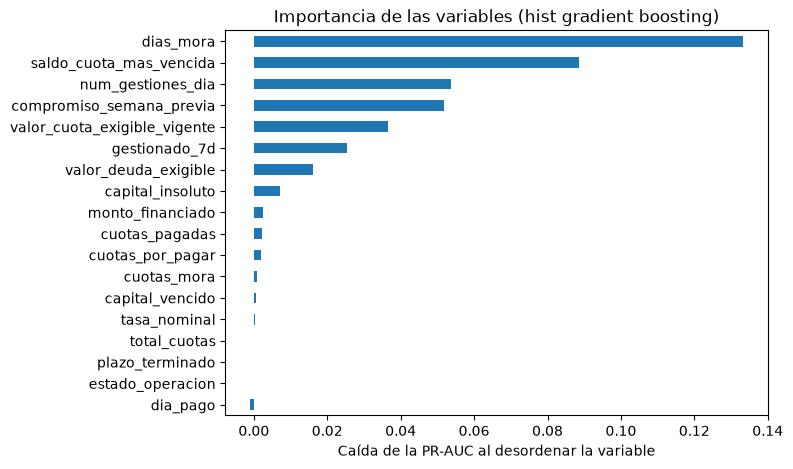

In [6]:
costos = []
for nombre, modelo, run_id in [(GANADOR, ganador, run_ganador), (SEGUNDO, segundo, run_segundo)]:
    inicio = time.perf_counter()
    modelo.predict_proba(X_prueba)
    segundos_prediccion = time.perf_counter() - inicio
    busqueda = padres.loc[nombre, "metrics.segundos_busqueda"]
    costos.append({"modelo": nombre, "segundos_busqueda_tuning": busqueda,
                   "segundos_prediccion_prueba": segundos_prediccion})
display(pd.DataFrame(costos).round(3))

importancia = permutation_importance(ganador, X_prueba, y_prueba, scoring="average_precision",
                                     n_repeats=5, random_state=42)
importancia = pd.Series(importancia.importances_mean, index=X_prueba.columns).sort_values()
importancia.plot(kind="barh", figsize=(7, 5))
plt.xlabel("Caída de la PR-AUC al desordenar la variable")
plt.title("Importancia de las variables (hist gradient boosting)")
plt.savefig("../docs/figuras/seleccion_importancia.png", bbox_inches="tight")
plt.show()

**Hallazgo: el boosting es más barato y su predicción se puede explicar por variables.**
- **Costo:** el tuning del boosting tardó 83 s frente a 486 s del random forest (casi 6 veces menos), y predice toda la prueba en 0.06 s frente a 0.16 s. Los dos son viables para generar la lista diaria.
- **Explicabilidad:** las variables que más pesan son `dias_mora`, `saldo_cuota_mas_vencida`, `num_gestiones_dia` y `compromiso_semana_previa` (la feature creada en el notebook 02), seguidas de `valor_cuota_exigible_vigente` y `gestionado_7d`. Coinciden con lo que un analista de cobranzas usaría para priorizar.
- `plazo_terminado`, `estado_operacion` y `dia_pago` casi no aportan: su información ya está en `dias_mora`, como anticipaba el notebook 02 (el 92% de los casos de plazo terminado están en el tramo +120).

## 7. Corrida final y Model Registry

Se registra una corrida final (`fase = final`, `candidato = final`) con el modelo ganador, sus métricas de prueba y de negocio. Luego, en el Model Registry `priorizacion-cartera-modelo`:
- **`champion`**: el ganador (desde la corrida final).
- **`challenger`**: el segundo mejor (desde su corrida de tuning).

In [7]:
NOMBRE = "priorizacion-cartera-modelo"
metricas_ganador = metrica_negocio(p_ganador * capital)

with mlflow.start_run(run_name="final hist gradient boosting") as corrida_final:
    mlflow.set_tags({"fase": "final", "candidato": "final", "familia": "boosting", "commit": commit})
    mlflow.log_params({"run_id_tuning": run_ganador, "tabla_origen": TABLA, "fin_entrenamiento": FIN_ENTRENAMIENTO,
                       "inicio_prueba": INICIO_PRUEBA, "huella_datos": huella_datos,
                       "capacidad_diaria": CAPACIDAD, "costo_gestion": COSTO_GESTION})
    mlflow.log_metrics({"pr_auc_prueba": average_precision_score(y_prueba, prob_ganador),
                        "pr_auc_cv_promedio": padres.loc[GANADOR, "metrics.pr_auc_cv_promedio"],
                        "pr_auc_cv_desviacion": padres.loc[GANADOR, "metrics.pr_auc_cv_desviacion"],
                        "pagos_en_lista": metricas_ganador["pagos_en_lista"],
                        "capital_normalizado_capturado": metricas_ganador["capital_normalizado_capturado"],
                        "recaudo_no_priorizado": metricas_ganador["recaudo_no_priorizado"]})
    firma = infer_signature(X_prueba.head(100), ganador.predict_proba(X_prueba.head(100))[:, 1])
    mlflow.sklearn.log_model(ganador, "modelo", signature=firma, input_example=X_prueba.head(5))

version_champion = mlflow.register_model(f"runs:/{corrida_final.info.run_id}/modelo", NOMBRE).version
version_challenger = mlflow.register_model(f"runs:/{run_segundo}/modelo", NOMBRE).version
cliente.set_registered_model_alias(NOMBRE, "champion", version_champion)
cliente.set_registered_model_alias(NOMBRE, "challenger", version_challenger)

print("Corrida final:", corrida_final.info.run_id)
print(f"{NOMBRE}: champion = versión {version_champion} | challenger = versión {version_challenger}")

Corrida final: aa2fdd0af2bc4b778a923d4676068f09
priorizacion-cartera-modelo: champion = versión 1 | challenger = versión 2


Successfully registered model 'priorizacion-cartera-modelo'.
Created version '1' of model 'priorizacion-cartera-modelo'.
Registered model 'priorizacion-cartera-modelo' already exists. Creating a new version of this model...
Created version '2' of model 'priorizacion-cartera-modelo'.


## 8. Reproducir la métrica desde el registro

Se carga el modelo **solo** desde el registro (`models:/priorizacion-cartera-modelo@champion`), sin usar ninguna variable de las celdas anteriores salvo los datos, y se recalcula la PR-AUC de prueba. Debe ser **exactamente** la registrada en la corrida final.

In [8]:
modelo_registro = mlflow.sklearn.load_model(f"models:/{NOMBRE}@champion")
pr_auc_reproducida = average_precision_score(y_prueba, modelo_registro.predict_proba(X_prueba)[:, 1])
pr_auc_registrada = cliente.get_run(corrida_final.info.run_id).data.metrics["pr_auc_prueba"]

print("PR-AUC registrada:  ", pr_auc_registrada)
print("PR-AUC reproducida: ", pr_auc_reproducida)
print("¿Iguales?:", np.isclose(pr_auc_registrada, pr_auc_reproducida, rtol=0, atol=1e-12))

PR-AUC registrada:   0.5199718905714561
PR-AUC reproducida:  0.5199718905714561
¿Iguales?: True


## 9. Exportar las corridas

El servidor de MLflow vive en el Codespace, así que todas las corridas del experimento se exportan a `docs/corridas.csv` con `mlflow.search_runs`.

In [9]:
todas = mlflow.search_runs(experiment_names=["priorizacion-cartera"])
todas.to_csv("../docs/corridas.csv", index=False)
print("Corridas exportadas:", len(todas))
todas["tags.fase"].value_counts()

Corridas exportadas: 101


tags.fase
tuning       93
candidato     5
baseline      2
final         1
Name: count, dtype: int64

## 10. Decisión

**Modelo ganador (`champion`): hist gradient boosting ajustado.** **Segundo (`challenger`): random forest ajustado.**

| Criterio | Hist gradient boosting | Random forest |
|---|---|---|
| PR-AUC CV por crédito | 0.459 ± 0.022 | 0.449 ± 0.022 |
| Pliegues ganados | 5 de 5 | 0 de 5 |
| PR-AUC en prueba | 0.520 | 0.497 |
| Pagos en la lista (4 días) | 1,008 | 988 |
| Brecha (sobreajuste) | 0.081 | 0.205 |
| Segundos de tuning / predicción | 83 / 0.06 | 486 / 0.16 |

La diferencia en CV es menor que la variación entre pliegues, así que la decisión no se basa solo en esa métrica: el boosting gana en todos los pliegues, en la prueba y en la métrica de negocio, sobreajusta menos y es más barato de entrenar. Frente a la regla de negocio que aproxima el proceso actual (mayor capital insoluto primero), captura un 67% más de pagos con la misma capacidad de 600 llamadas diarias.